In [2]:
import pandas as pd #grabbing the imports
import mysql.connector
import matplotlib.pyplot as plt


     ---------------------------------------- 2.1/2.1 MB 2.2 MB/s eta 0:00:00
     ---------------------------------------- 45.0/45.0 kB ? eta 0:00:00
     -------------------------------------- 298.9/298.9 kB 4.7 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [ ]:
from sqlalchemy import create_engine  # i get SQLAlchemy to get the code to run without crashing the kernal.
#note that this takes about 4 minutes to run

# The database connection details
host = "128.198.162.191"
database = "company"
user = "infscompany"
password = "yeadata"

# Connection string that gets me into the database
connection_string = f"mysql+pymysql://{user}:{password}@{host}/{database}"

try:
    # The Engine is a factory that can create new database connections for us, which also holds onto connections inside of a Connection Pool for fast reuse (grabbed form https://docs.sqlalchemy.org/en/20/orm/quickstart.html#create-an-engine )
    engine = create_engine(connection_string)
    # Fetch data into a Pandas DataFrame
    query = "SELECT * FROM sales;"
    sales_data = pd.read_sql(query, engine)
    # Shows the first few rows.
    print("\nSales Data Preview:")
    print(sales_data.head())
    # This saves the file localy to work with it better
    csv_file_path = "sales_data.csv"
    sales_data.to_csv(csv_file_path, index=False) #note that this is saved to downloads!
    print(f"Data exported to {csv_file_path}")

except Exception as e: # shoes if there is an error
    print(f"Error: {e}")

In [3]:
df = pd.read_csv("C:\\Users\\Do it ball\\Downloads\\sales_data.csv") #this is the sales. Also find the file that was downloaded in downloads and copy the path!
print(df)


            PK  Store  Dept   SalesDate  Weekly_Sales  IsHoliday
0            1    1.0   1.0  2019-02-05    25173.7450          0
1            2    1.0   1.0  2019-02-12    46499.8849          1
2            3    1.0   1.0  2019-02-19    42011.5055          0
3            4    1.0   1.0  2019-02-26    19597.5754          0
4            5    1.0   1.0  2019-03-05    22046.1790          0
...        ...    ...   ...         ...           ...        ...
372797  372798   46.0  95.0  2021-06-30        0.0000          0
372798  372799   46.0  96.0  2021-06-30        0.0000          0
372799  372800   46.0  97.0  2021-06-30        0.0000          0
372800  372801   46.0  98.0  2021-06-30        0.0000          0
372801  372802   46.0  99.0  2021-06-30        0.0000          0

[372802 rows x 6 columns]


In [18]:
column_names = ['PK', 'Store', 'Dept', 'SalesDate', 'Weekly_Sales', 'IsHoliday'] #me making column names for the file

df = pd.read_csv(r"C:\\Users\\Do it ball\\Downloads\\sales_data.csv", names= column_names, usecols=range(len(column_names)), on_bad_lines= 'skip',)

df.head(11)

C:\Users\Do it ball\AppData\Local\Temp\ipykernel_27032\784713907.py:3: DtypeWarning: Columns (0,1,2,4,5) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(r"C:\\Users\\Do it ball\\Downloads\\sales_data.csv", names= column_names, usecols=range(len(column_names)), on_bad_lines= 'skip',)


,PK,Store,Dept,SalesDate,Weekly_Sales,IsHoliday
0,PK,Store,Dept,SalesDate,Weekly_Sales,IsHoliday
1,1,1.0,1.0,2019-02-05,25173.745,0
2,2,1.0,1.0,2019-02-12,46499.8849,1
3,3,1.0,1.0,2019-02-19,42011.5055,0
4,4,1.0,1.0,2019-02-26,19597.5754,0
5,5,1.0,1.0,2019-03-05,22046.179,0
6,6,1.0,1.0,2019-03-12,21253.8239,0
7,7,1.0,1.0,2019-03-19,22358.0064,0
8,8,1.0,1.0,2019-03-26,26491.5021,0
9,9,1.0,1.0,2019-04-02,57831.0143,0


In [ ]:
df.Dept

0         Dept
1          1.0
2          1.0
3          1.0
4          1.0
          ... 
372798    95.0
372799    96.0
372800    97.0
372801    98.0
372802    99.0
Name: Dept, Length: 372803, dtype: object

In [6]:
print(df.columns)

Index(['PK', 'Store', 'Dept', 'SalesDate', 'Weekly_Sales', 'IsHoliday'], dtype='object')


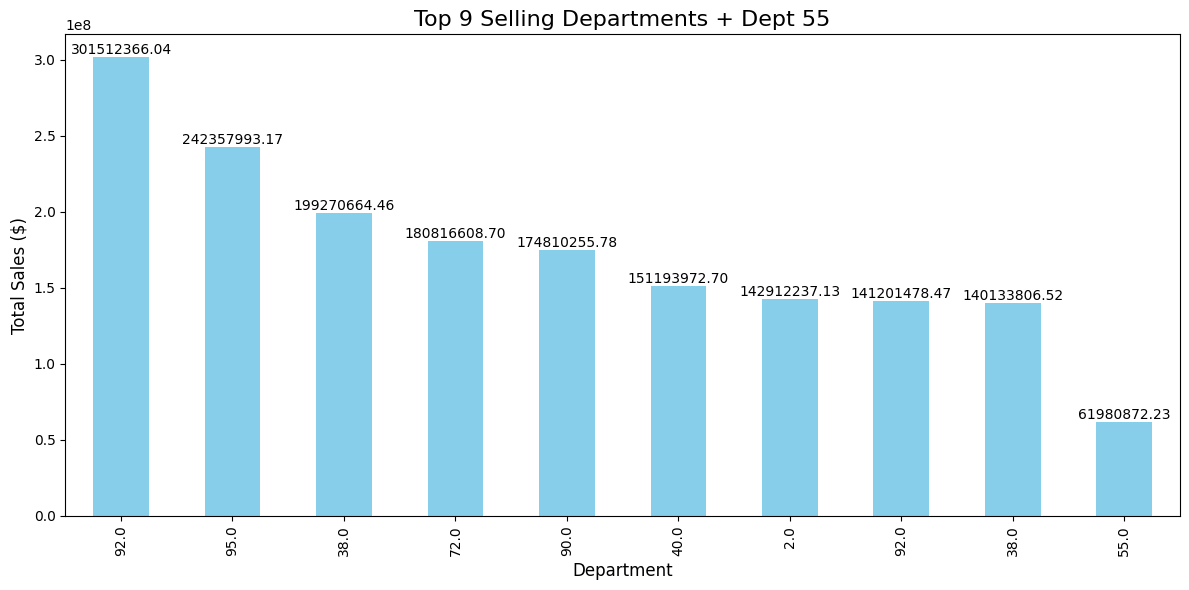

In [19]:

# Ensure Weekly_Sales is numeric.
df['Weekly_Sales'] = pd.to_numeric(df['Weekly_Sales'], errors='coerce')

# Drops rows with NaN values
df = df.dropna(subset=['Weekly_Sales'])
department_sales = df.groupby('Dept')['Weekly_Sales'].sum()
dept_55_sales = department_sales.get(55.0, 0)
# Grabs teh top 9 departments
top_departments = department_sales.sort_values(ascending=False).head(9)
# Combine the top departments and department 55 using pd.concat
top_departments = pd.concat([top_departments, pd.Series(dept_55_sales, index=[55.0,])])
# Sort again to ensure department 55 appears in the correct place
top_departments = top_departments.sort_values(ascending=False)

# Plot the bar chart
plt.figure(figsize=(12, 6))
top_departments.plot(kind='bar', color='skyblue')

#labes and stuff
plt.title('Top 9 Selling Departments + Dept 55', fontsize=16)
plt.xlabel('Department', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)

# This displays the values on top of the bars
for i, v in enumerate(top_departments):
    plt.text(i, v + 10000, f'{v:.2f}', ha='center', va='bottom', fontsize=10)

# Shows the plot
plt.tight_layout()
plt.show()


c:\Users\Do it ball\Downloads\BI-XTZ\installer_files\env\Lib\site-packages\pandas\core\indexes\base.py:7588: FutureWarning: Dtype inference on a pandas object (Series, Index, ExtensionArray) is deprecated. The Index constructor will keep the original dtype in the future. Call `infer_objects` on the result to get the old behavior.
  return Index(sequences[0], name=names)


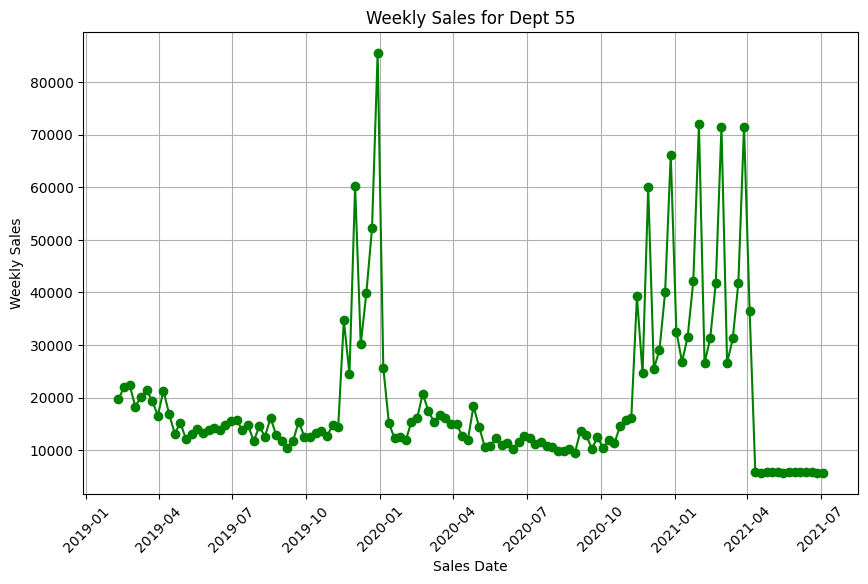

In [9]:
filtered_df = df[df['Dept'] == 55.0].copy()  
# SalesDate to datetime 
filtered_df.loc[:, 'SalesDate'] = pd.to_datetime(filtered_df['SalesDate'])
#Extra plotting to get the data to not look wonkey
filtered_df.set_index('SalesDate', inplace=True)
weekly_sales = filtered_df.resample('W').agg({'Weekly_Sales': 'mean'}).reset_index()
# Plotting the data 
plt.figure(figsize=(10, 6))
plt.plot(weekly_sales['SalesDate'], weekly_sales['Weekly_Sales'], marker='o', linestyle='-', color='g')
plt.title('Weekly Sales for Dept 55')
plt.xlabel('Sales Date')
plt.ylabel('Weekly Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [10]:
#note that this takes about 2 minutes to run this is also a new data file!
# The database connection details
host = "128.198.162.191"
database = "company"
user = "infscompany"
password = "yeadata"
# Connection string that gets me into the database
connection_string = f"mysql+pymysql://{user}:{password}@{host}/{database}"
try:
    # The Engine is a factory that can create new database connections for us, which also holds onto connections inside of a Connection Pool for fast reuse (grabbed form https://docs.sqlalchemy.org/en/20/orm/quickstart.html#create-an-engine )
    engine = create_engine(connection_string)
    # Fetch data into a Pandas DataFrame
    query = "SELECT * FROM expenses_month_dept;"
    sales_data = pd.read_sql(query, engine)
    # Shows the first few rows.
    print("\nstores Data Preview:")
    print(sales_data.head())
    # This saves the file localy to work with it better
    csv_file_path = "expenses_month_dept.csv"
    sales_data.to_csv(csv_file_path, index=False)
    print(f"Data exported to {csv_file_path}")
except Exception as e: #if there is an error it will show
    print(f"Error: {e}")


stores Data Preview:
   Store ExpenseDate  Dept  Expense_Allocation
0    1.0  2019-07-31  35.0            37729.43
1    1.0  2019-07-31  36.0            37729.43
2    1.0  2019-07-31  37.0            37729.43
3    1.0  2019-07-31  38.0            18864.72
4    1.0  2019-07-31  39.0            37729.43
Data exported to expenses_month_dept.csv


In [11]:

column_names = ['Store', 'ExpenseDate', 'Dept', 'Expense_Allocation',] #me defining new column names for the new data file

df = pd.read_csv(r"C:\\Users\\Do it ball\\Downloads\\expenses_month_dept.csv", names= column_names, usecols=range(len(column_names)), on_bad_lines= 'skip',)
df.head(25)

,Store,ExpenseDate,Dept,Expense_Allocation
0,Store,ExpenseDate,Dept,Expense_Allocation
1,1.0,2019-07-31,35.0,37729.43
2,1.0,2019-07-31,36.0,37729.43
3,1.0,2019-07-31,37.0,37729.43
4,1.0,2019-07-31,38.0,18864.72
5,1.0,2019-07-31,39.0,37729.43
6,1.0,2019-07-31,40.0,75458.86
7,1.0,2019-07-31,41.0,75458.86
8,1.0,2019-07-31,42.0,7545.89
9,1.0,2019-07-31,43.0,18864.72


In [143]:
print(df.columns)

Index(['Store', 'ExpenseDate', 'Dept', 'Expense_Allocation'], dtype='object')


In [12]:
#makes columns  numeric
df['Dept'] = pd.to_numeric(df['Dept'], errors='coerce')
df['Expense_Allocation'] = pd.to_numeric(df['Expense_Allocation'], errors='coerce')

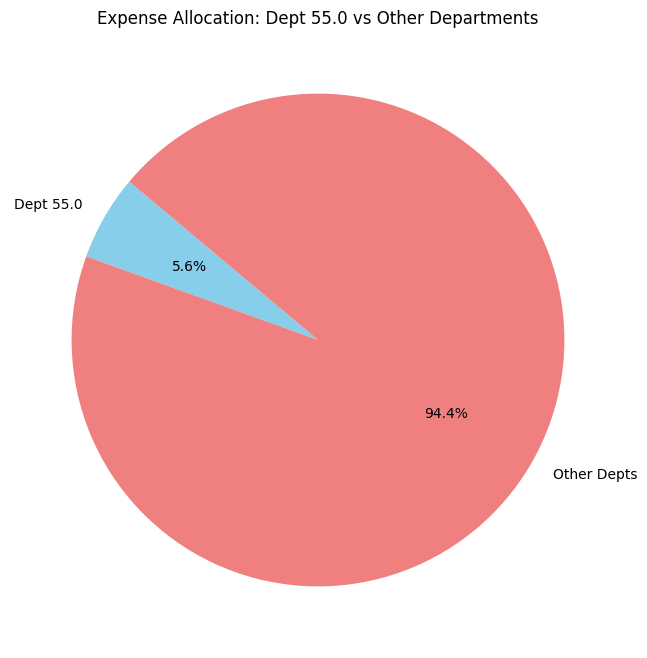

In [13]:

# Drop rows with NaN values
df = df.dropna(subset=['Dept', 'Expense_Allocation'])
# This Groups the data
dept_55_allocation = df.loc[df['Dept'] == 55.0, 'Expense_Allocation'].sum()
other_allocation = df.loc[df['Dept'] != 55.0, 'Expense_Allocation'].sum()
# Grabs the data
labels = ['Dept 55.0', 'Other Depts']
sizes = [dept_55_allocation, other_allocation]
# (i had a lot of issues making my data numaric so this checks that)
sizes = [float(x) for x in sizes]
# Makes the pie chart
plt.figure(figsize=(8, 8))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=140, colors=['skyblue', 'lightcoral'])
plt.title('Expense Allocation: Dept 55.0 vs Other Departments')
plt.show()


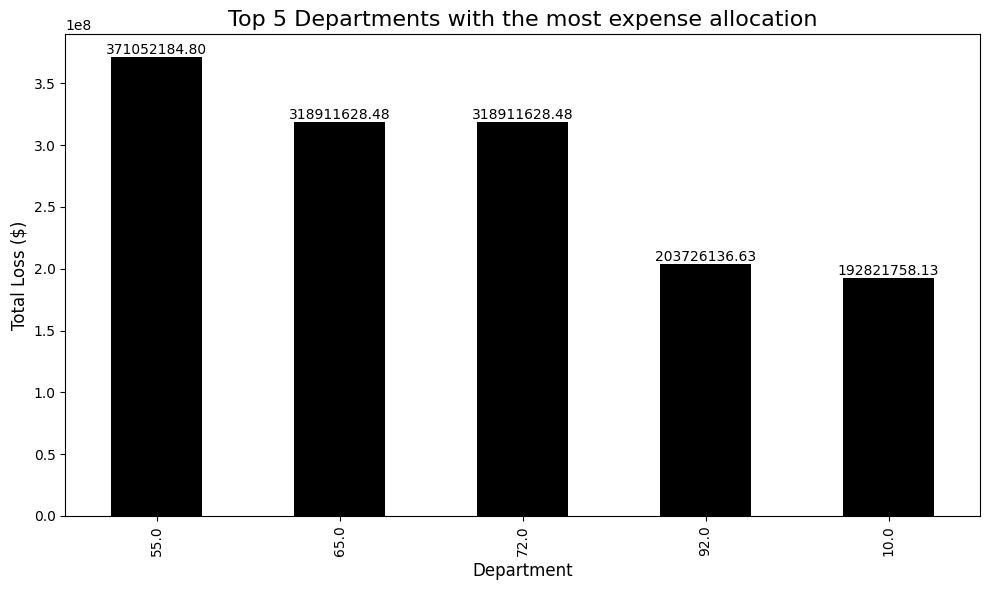

In [14]:
#this code shows the losses of the top 5 DepDepartments
department_losses = df.groupby('Dept')['Expense_Allocation'].sum()
top_5_departments = department_losses.sort_values(ascending=False).head(5)
plt.figure(figsize=(10, 6))
top_5_departments.plot(kind='bar', color='black')
plt.title('Top 5 Departments with the most expense allocation', fontsize=16)
plt.xlabel('Department', fontsize=12)
plt.ylabel('Total Loss ($)', fontsize=12)
#this shows the losses at the top of teh bar
for i, v in enumerate(top_5_departments):
    plt.text(i, v + 50000, f'{v:.2f}', ha='center', va='bottom', fontsize=10)

# plots
plt.tight_layout()
plt.show()